# Comparative Analysis of Classification Algorithms Using a Multiclass Dataset
## student name: Carrinton Ayuk
## student num: ST10541422

### Introduction

This study compares different classification algorithms on a multiclass dataset. The aim is to build and evaluate multiple machine learning models and determine which algorithm performs best. The Iris dataset was selected because it is a well-known multiclass dataset containing three flower species: Setosa, Versicolor, and Virginica. The models are evaluated using accuracy, precision, recall, F1-score, and confusion matrices.

In [9]:
# We load and inspect the dataset, importing all libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["target"] = iris.target
df["species"] = df["target"].map({
    0: "setosa",
    1: "versicolor",
    2: "virginica"
})

print(df.head())
print(df.shape)
print(df.info())
print(df["species"].value_counts())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target species  
0       0  setosa  
1       0  setosa  
2       0  setosa  
3       0  setosa  
4       0  setosa  
(150, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4  

### Dataset Exploration and Preparation

The Iris dataset was selected for this classification task because it is a multiclass dataset with three target classes. It contains 150 records and four numeric predictor variables. The target variable represents three different species of iris flowers. The dataset is suitable because it is structured, balanced across classes, and contains no missing values.

       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)      target  
count        150.000000  150.000000  
mean           1.199333    1.000000  
std            0.762238    0.819232  
min            0.100000    0.000000  
25%            0.300000    0.000000  
50%            1.300000    1.000000  
75%            1.800000    2.000000  
max            2.500000    2.000000  


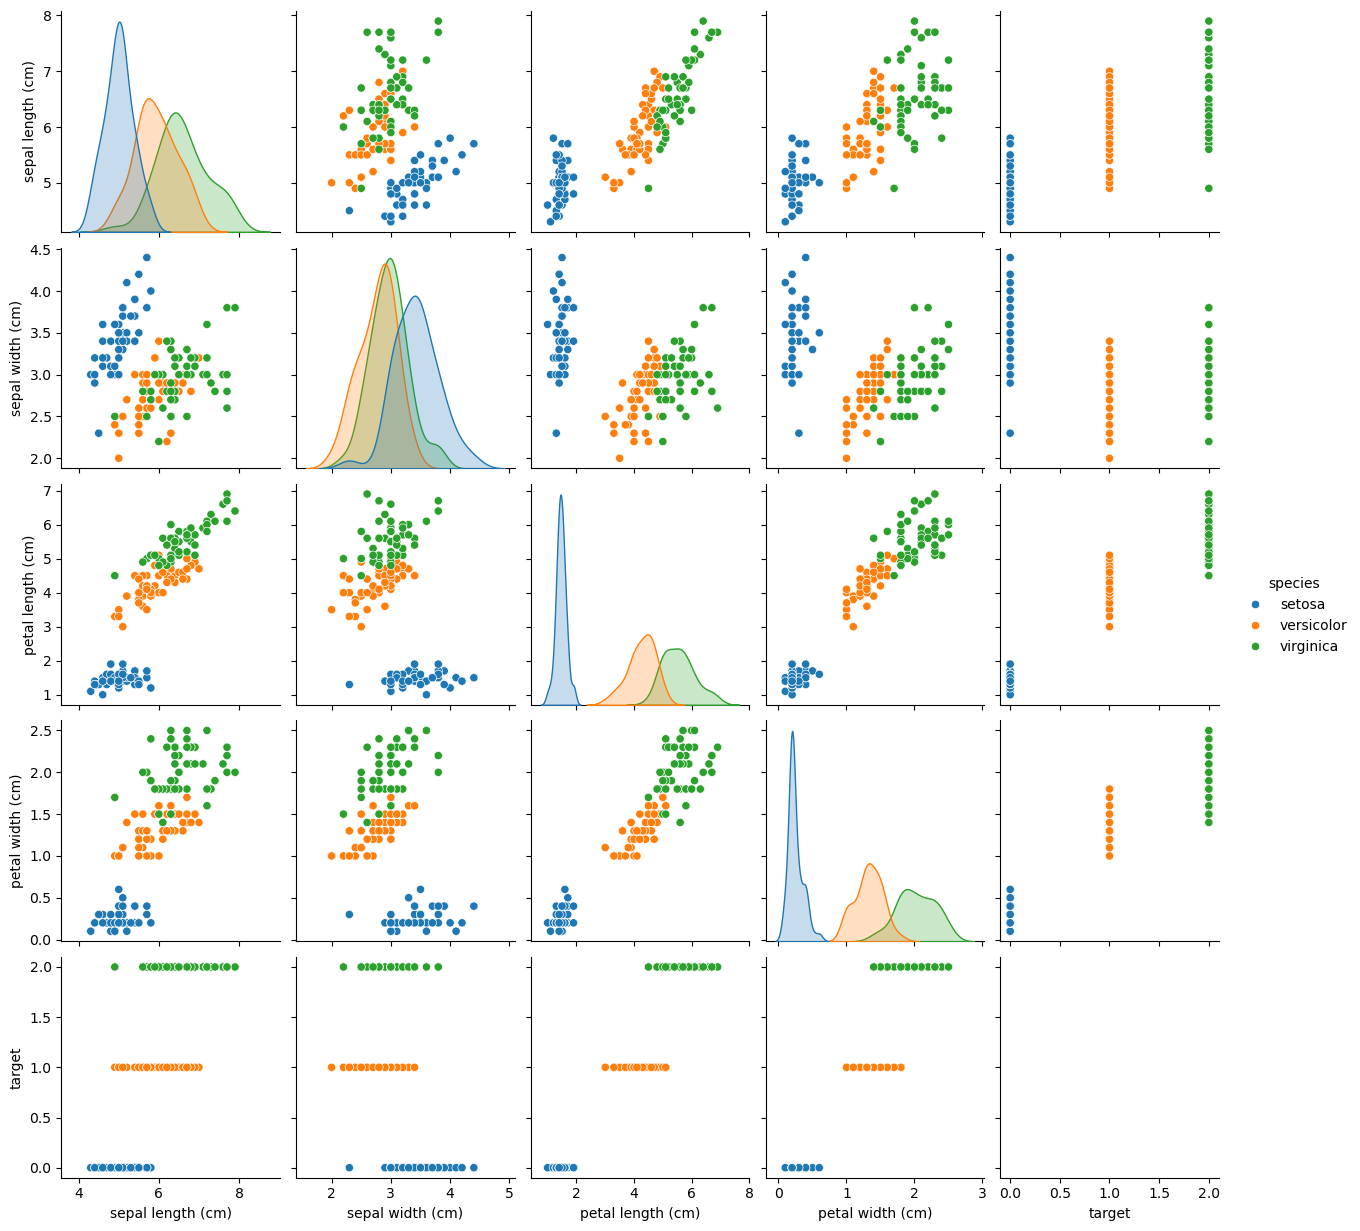

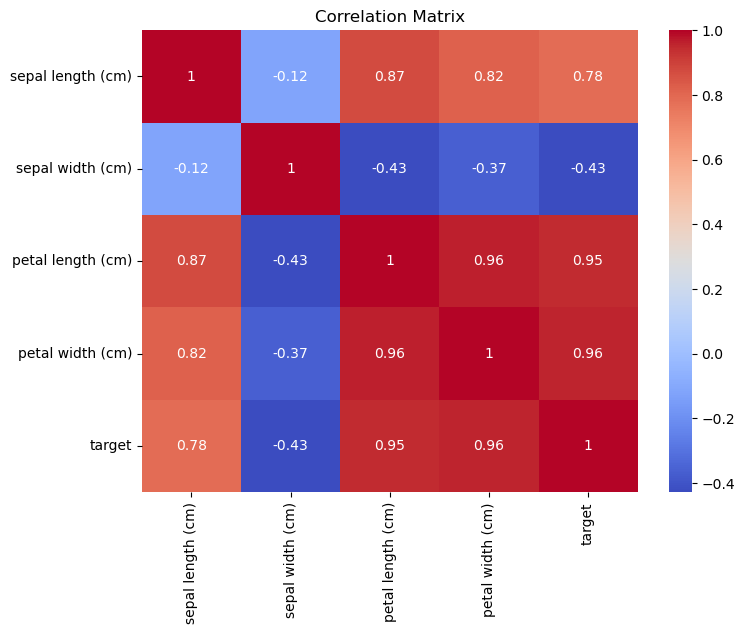

In [3]:
# Exploratory Data Analysis 

import seaborn as sns

print(df.describe())

sns.pairplot(df, hue="species")
plt.show()

plt.figure(figsize=(8,6))
sns.heatmap(df.drop(columns=["species"]).corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

The exploratory analysis shows that the dataset is balanced across the three flower species. The pairplot indicates that some classes are clearly separable, especially Setosa, while Versicolor and Virginica show slight overlap. The correlation matrix shows relationships among the numerical features, such as petal length and petal width.

In [4]:
# We now prepare data for modelling 

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[iris.feature_names]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (120, 4)
Testing set shape: (30, 4)


 ## Data Preparation

The predictor variables were separated from the target variable. The dataset was then split into training and testing sets using an 80% / 20% ratio. Standardization was used for algorithms that are sensitive to feature scale, which are Logistic Regression and K-Nearest Neighbors.

In [12]:
# Build Classification Models
# Import all required libraries for modelling 
models = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

## Logistic Regression

Logistic Regression Results
Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1 Score: 0.9333333333333333


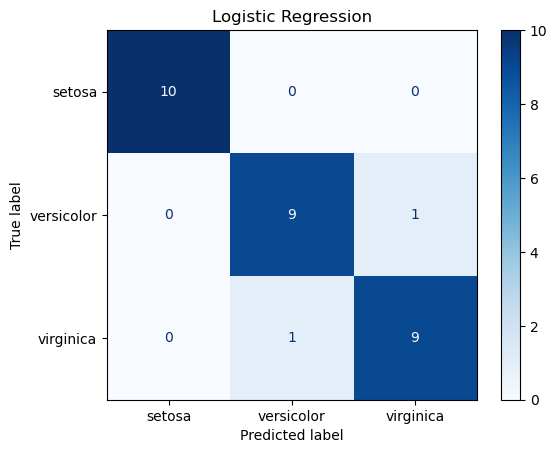

In [24]:
lr_model = LogisticRegression(max_iter=200)
lr_model.fit(X_train_scaled, y_train)
lr_pred = lr_model.predict(X_test_scaled)

lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred, average="weighted")
lr_recall = recall_score(y_test, lr_pred, average="weighted")
lr_f1 = f1_score(y_test, lr_pred, average="weighted")

print("Logistic Regression Results")
print("Accuracy:", lr_accuracy)
print("Precision:", lr_precision)
print("Recall:", lr_recall)
print("F1 Score:", lr_f1)

lr_cm = confusion_matrix(y_test, lr_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=lr_cm, display_labels=iris.target_names)
disp.plot(cmap="Blues")
plt.title("Logistic Regression")
plt.show()

## K-Nearest Neighbors

KNN Results
Accuracy: 0.9333333333333333
Precision: 0.9444444444444445
Recall: 0.9333333333333333
F1 Score: 0.9326599326599326


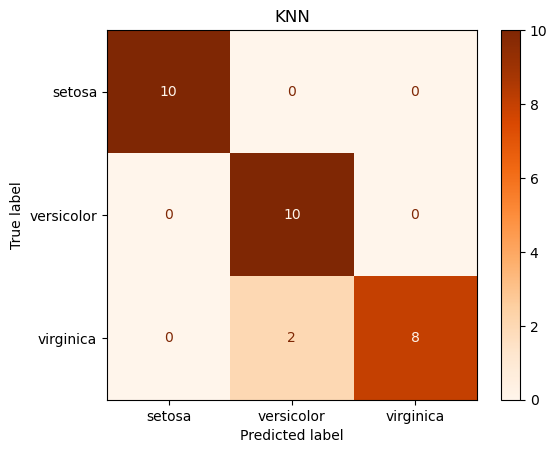

In [23]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
knn_pred = knn_model.predict(X_test_scaled)

knn_accuracy = accuracy_score(y_test, knn_pred)
knn_precision = precision_score(y_test, knn_pred, average="weighted")
knn_recall = recall_score(y_test, knn_pred, average="weighted")
knn_f1 = f1_score(y_test, knn_pred, average="weighted")

print("KNN Results")
print("Accuracy:", knn_accuracy)
print("Precision:", knn_precision)
print("Recall:", knn_recall)
print("F1 Score:", knn_f1)

knn_cm = confusion_matrix(y_test, knn_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=knn_cm, display_labels=iris.target_names)
disp.plot(cmap="Oranges")
plt.title("KNN")
plt.show()

# Decision Tree

Decision Tree Results
Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1 Score: 0.9333333333333333


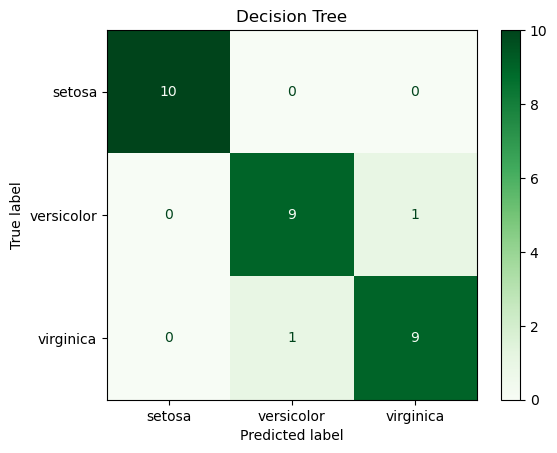

In [22]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred, average="weighted")
dt_recall = recall_score(y_test, dt_pred, average="weighted")
dt_f1 = f1_score(y_test, dt_pred, average="weighted")

print("Decision Tree Results")
print("Accuracy:", dt_accuracy)
print("Precision:", dt_precision)
print("Recall:", dt_recall)
print("F1 Score:", dt_f1)

dt_cm = confusion_matrix(y_test, dt_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=dt_cm, display_labels=iris.target_names)
disp.plot(cmap="Greens")
plt.title("Decision Tree")
plt.show()

# Random Forest

Random Forest Results
Accuracy: 0.9
Precision: 0.9023569023569024
Recall: 0.9
F1 Score: 0.8997493734335839


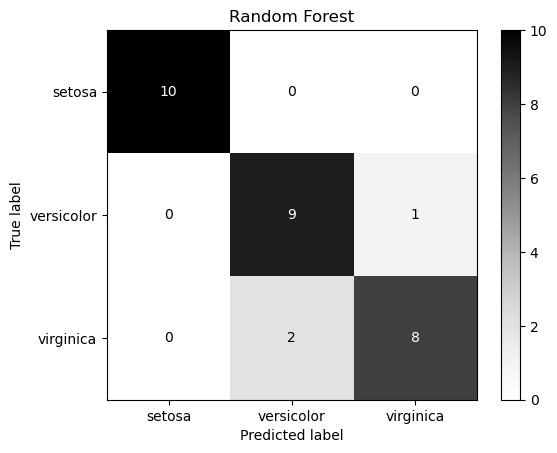

In [31]:
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred, average="weighted")
rf_recall = recall_score(y_test, rf_pred, average="weighted")
rf_f1 = f1_score(y_test, rf_pred, average="weighted")

print("Random Forest Results")
print("Accuracy:", rf_accuracy)
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1 Score:", rf_f1)

rf_cm = confusion_matrix(y_test, rf_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=rf_cm, display_labels=iris.target_names)
disp.plot(cmap="Greys")
plt.title("Random Forest")
plt.show()

## Comparison table

In [32]:
results_df = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN", "Decision Tree", "Random Forest"],
    "Accuracy": [lr_accuracy, knn_accuracy, dt_accuracy, rf_accuracy],
    "Precision": [lr_precision, knn_precision, dt_precision, rf_precision],
    "Recall": [lr_recall, knn_recall, dt_recall, rf_recall],
    "F1 Score": [lr_f1, knn_f1, dt_f1, rf_f1]
})

results_df = results_df.sort_values(by="Accuracy", ascending=False)
print(results_df)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.933333   0.933333  0.933333  0.933333
1                  KNN  0.933333   0.944444  0.933333  0.932660
2        Decision Tree  0.933333   0.933333  0.933333  0.933333
3        Random Forest  0.900000   0.902357  0.900000  0.899749


## Comparison of models ( chart )

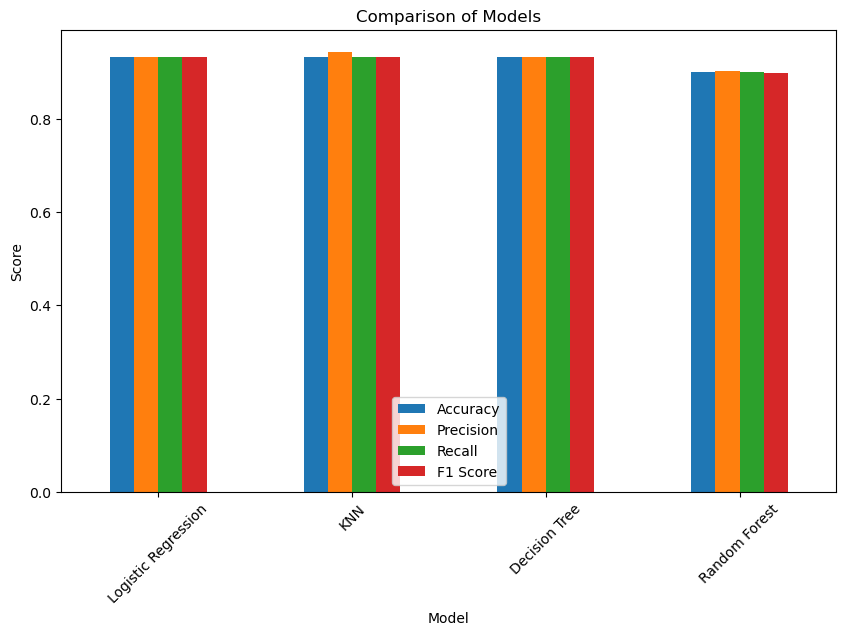

In [35]:
# Comparison of models on a chart based on Accuracy, Recall, F1 score, and Precision.

results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    kind="bar", figsize=(10,6)
)
plt.title("Comparison of Models")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.show()

## Comparison of Models

The four classification models were compared using accuracy, precision, recall, and F1-score. The model with the highest values across these metrics is considered the best-performing model. The confusion matrices also help to identify the specific classes that were classified correctly and where misclassifications occurred.

## Interpretation of Results

Logistic Regression, KNN, and Decision Tree all achieved the highest accuracy of 0.9333. Random Forest performed slightly lower with an accuracy of 0.9000.

Logistic Regression and Decision Tree produced the highest F1-score of 0.9333, showing the best balance between precision and recall. KNN had the highest precision of 0.9444, but its F1-score was slightly lower.

The confusion matrices show that most classes were predicted correctly, with only a few classification errors between similar classes.

Based on the results, Logistic Regression is recommended because it achieved high accuracy, a strong F1-score, and is easier to interpret than the other models.

### Answers to Related Questions

#### --Which model achieved the highest accuracy?
Logistic Regression, KNN, and Decision Tree all achieved the highest accuracy of 0.9333.
#### --Which model produced the best balance between precision and recall?
Logistic Regression and Decision Tree, as shown by their F1-score of 0.9333.
#### --Which model produced the highest F1-score?
Logistic Regression and Decision Tree achieved the highest F1-score of 0.9333.
#### --What insights can be drawn from the confusion matrices?
The confusion matrices show that most observations were classified correctly, with only a few misclassifications between similar classes. This suggests that the models performed well overall.
#### --Which model would you recommend and why?
Logistic Regression, because it performed very well and is easy to explain, F1 score is high and it provides a much easy interpretation model than others.